# Chatbots clássicos com PLN e Machine Learning

**Tema:** reconhecimento de intenções em atendimento bancário usando **TF-IDF + SVM linear**.  
**Ambiente:** Google Colab, CPU.  
**Dados:** BANKING77 (inglês), com 77 intenções.

### Objetivos
1. Explicar como um chatbot de domínio fechado reconhece intenções.
2. Treinar e avaliar um classificador de intenções com Scikit-learn.
3. Conectar previsões a respostas predefinidas e implementar um fallback simples.
4. Investigar erros e limitações da abordagem clássica.

> **Importante:** este chatbot é uma demonstração didática. Não acessa contas, não realiza pagamentos e não executa operações bancárias.

## 1. Como funciona um chatbot clássico?

Considere a mensagem: **“I lost my card yesterday.”**

- **Intenção:** o objetivo do usuário; neste caso, comunicar a perda de um cartão.
- **Entidade:** representa uma informação específica extraída da mensagem, que ajuda a contextualizar ou especificar a intenção.Um detalhe extraído do texto, como *yesterday* (data relativa) ou "card" (objeto perdido). **Este notebook classifica intenções; não treina um extrator de entidades.**
- **Gerenciamento de diálogo:** decide como o sistema deve prosseguir.
- **Resposta:** texto previamente associado à intenção prevista.

**Pipeline:** mensagem → TF-IDF → SVM linear → intenção → resposta cadastrada/fallback.

**Por que TF-IDF?** Converte o texto em um vetor numérico esparso. Um termo frequente em uma mensagem mas relativamente raro nos documentos do corpus ganha maior peso. Um **n-grama** representa uma sequência de *n* palavras: `(1, 2)` usa palavras isoladas e pares consecutivos.

**Por que SVM linear?** O `LinearSVC` aprende fronteiras lineares que separam as classes no espaço vetorial. É uma abordagem tradicional, rápida em bases moderadas e bastante adequada como baseline de classificação de texto. Ele não compreende linguagem como uma pessoa e não produz respostas espontaneamente.

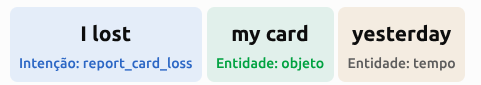

## 2. Bibliotecas e reprodutibilidade

Usaremos bibliotecas amplamente disponíveis no Colab.

In [ ]:
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print('Python:', sys.version.split()[0])
print('Scikit-learn:', sklearn.__version__)
print('Processamento: CPU; nenhuma GPU é necessária.')

Python: 3.13.16
Scikit-learn: 1.6.1
Processamento: CPU; nenhuma GPU é necessária.


## 3. Conhecendo o dataset BANKING77

O [BANKING77](https://github.com/PolyAI-LDN/task-specific-datasets) contém mensagens reais ou representativas de atendimento bancário, em inglês, rotuladas em 77 intenções. Utilizaremos a **divisão oficial de teste**, reservada até a avaliação final.

Os links apontam para arquivos CSV públicos do repositório da PolyAI. Para executar, é necessário acesso à internet somente no download inicial.

In [ ]:
BASE_URL = 'https://raw.githubusercontent.com/PolyAI-LDN/task-specific-datasets/master/banking_data'
t0 = time.perf_counter()
train_raw = pd.read_csv(f'{BASE_URL}/train.csv')
test_df = pd.read_csv(f'{BASE_URL}/test.csv')

required = {'text', 'category'}
assert required.issubset(train_raw.columns) and required.issubset(test_df.columns), 'Colunas esperadas não encontradas.'
train_raw = train_raw[['text','category']].dropna().reset_index(drop=True)
test_df = test_df[['text','category']].dropna().reset_index(drop=True)
assert set(test_df['category']).issubset(set(train_raw['category'])), 'Existem categorias no teste ausentes no treino.'

print(f'Download e leitura: {time.perf_counter()-t0:.2f} s')
print(f'Exemplos oficiais — treino: {len(train_raw):,} | teste: {len(test_df):,}')
print(f'Intenções: {train_raw.category.nunique()}')
display(train_raw.sample(8, random_state=RANDOM_STATE))

Download e leitura: 0.54 s
Exemplos oficiais — treino: 10,003 | teste: 3,080
Intenções: 77


,text,category
6883,Is it possible for me to change my PIN number?,change_pin
5836,I'm not sure why my card didn't work,declined_card_payment
8601,I don't think my top up worked,top_up_failed
2545,Can you explain why my payment was charged a fee?,card_payment_fee_charged
8697,How long does a transfer from a UK account tak...,balance_not_updated_after_bank_transfer
5573,Why am I getting declines when trying to make ...,declined_transfer
576,What is the $1 transaction on my account?,extra_charge_on_statement
6832,It looks like my card payment was sent back.,reverted_card_payment?


### Divisão treino / validação / teste

A **validação** serve para analisar escolhas durante o desenvolvimento; o **teste** fornece a avaliação final e não deve ser usado para ajustar o modelo. A separação é estratificada, preservando aproximadamente a proporção de cada intenção.

,Conjunto,Exemplos,Intenções
0,Treinamento,8502,77
1,Validação,1501,77
2,Teste oficial,3080,77


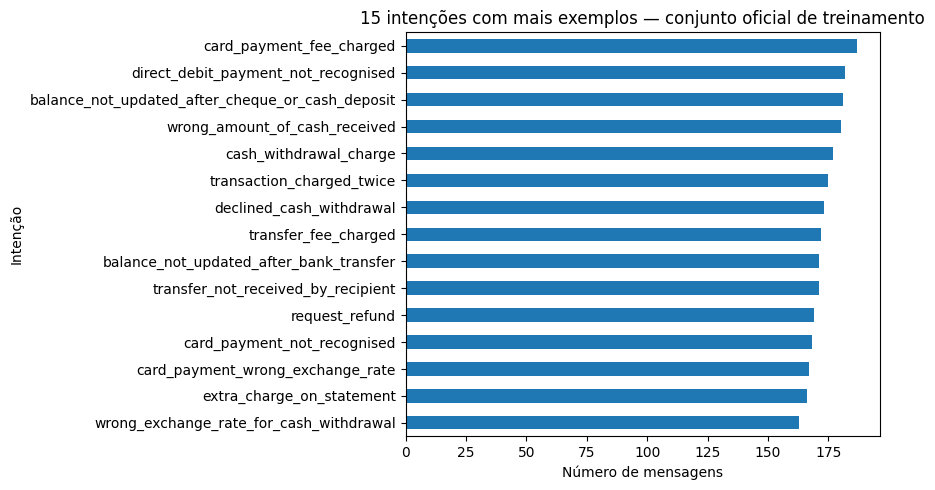

In [ ]:
train_df, val_df = train_test_split(
    train_raw, test_size=0.15, random_state=RANDOM_STATE,
    stratify=train_raw['category']
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

splits = pd.DataFrame({
    'Conjunto': ['Treinamento', 'Validação', 'Teste oficial'],
    'Exemplos': [len(train_df), len(val_df), len(test_df)],
    'Intenções': [train_df.category.nunique(), val_df.category.nunique(), test_df.category.nunique()]
})
display(splits)

counts = train_raw.category.value_counts().head(15).sort_values()
ax = counts.plot.barh(figsize=(9,5), title='15 intenções com mais exemplos — conjunto oficial de treinamento')
ax.set_xlabel('Número de mensagens')
ax.set_ylabel('Intenção')
plt.tight_layout()
plt.show()

## 4. TF-IDF + SVM: treinamento

`Pipeline` é uma maneira segura de ajustar a transformação de texto **apenas nos dados de treinamento**, evitando vazamento de informação (*data leakage*). O pré-processamento para uma nova frase será idêntico ao do treinamento.

- `ngram_range=(1,2)`: unigramas e bigramas;
- `sublinear_tf=True`: substitui a frequência bruta por uma escala logarítmica;
- `LinearSVC`: classificador linear multiclasse.

O modelo usa **pesos aprendidos** e não regras manuais de correspondência de palavras.

In [ ]:
def make_pipeline(ngram_range=(1,2)):
    return Pipeline([
        ('tfidf', TfidfVectorizer(ngram_range=ngram_range, sublinear_tf=True)),
        ('svm', LinearSVC(random_state=RANDOM_STATE, max_iter=3000))
    ])

model = make_pipeline()
t0 = time.perf_counter()
model.fit(train_df['text'], train_df['category'])
training_seconds = time.perf_counter() - t0

vocabulary_size = len(model.named_steps['tfidf'].vocabulary_)
print(f'Treinamento: {training_seconds:.2f} s')
print(f'Vocabulário TF-IDF (termos e n-gramas): {vocabulary_size:,}')
print(f'Intenções aprendidas: {len(model.classes_)}')

Treinamento: 2.61 s
Vocabulário TF-IDF (termos e n-gramas): 21,595
Intenções aprendidas: 77


## 5. Validação e avaliação final

**Métricas:**
- *Accuracy*: proporção de previsões corretas;
- *Precision macro*: precisão média entre as classes, com peso igual para cada intenção;
- *Recall macro*: sensibilidade média entre as classes;
- *F1 macro*: média dos F1 de cada classe.

**Atenção:** as métricas medem a identificação da intenção, **não** a qualidade de um diálogo completo.

In [ ]:
def evaluate_classifier(trained_model, frame, split_name):
    t0 = time.perf_counter()
    pred = trained_model.predict(frame['text'])
    elapsed = time.perf_counter() - t0
    precision, recall, f1, _ = precision_recall_fscore_support(
        frame['category'], pred, average='macro', zero_division=0
    )
    metrics = {
        'Conjunto': split_name,
        'Accuracy': accuracy_score(frame['category'], pred),
        'Precision macro': precision,
        'Recall macro': recall,
        'F1 macro': f1,
        'Tempo total inferência (s)': elapsed,
        'ms/mensagem': elapsed * 1000 / len(frame)
    }
    return metrics, np.asarray(pred)

val_metrics, val_pred = evaluate_classifier(model, val_df, 'Validação')
test_metrics, test_pred = evaluate_classifier(model, test_df, 'Teste oficial')
metric_table = pd.DataFrame([val_metrics, test_metrics]).set_index('Conjunto')
display(metric_table.style.format({
    'Accuracy':'{:.3f}', 'Precision macro':'{:.3f}', 'Recall macro':'{:.3f}',
    'F1 macro':'{:.3f}', 'Tempo total inferência (s)':'{:.3f}',
    'ms/mensagem':'{:.3f}'
}))
print(f'Tempo de treinamento: {training_seconds:.2f} s')

,Accuracy,Precision macro,Recall macro,F1 macro,Tempo total inferência (s),ms/mensagem
Conjunto,,,,,,
Validação,0.889,0.898,0.891,0.891,0.108,0.072
Teste oficial,0.886,0.890,0.886,0.886,0.128,0.042


Tempo de treinamento: 2.61 s


### 5.1. Onde o classificador erra?

A seguir, identificamos as **10 classes verdadeiras com mais erros** no conjunto de teste. A matriz mostra apenas exemplos cujas classes verdadeiras e previstas pertencem a esse subconjunto; por isso, é **parcial** e não representa a matriz completa de 77 classes.

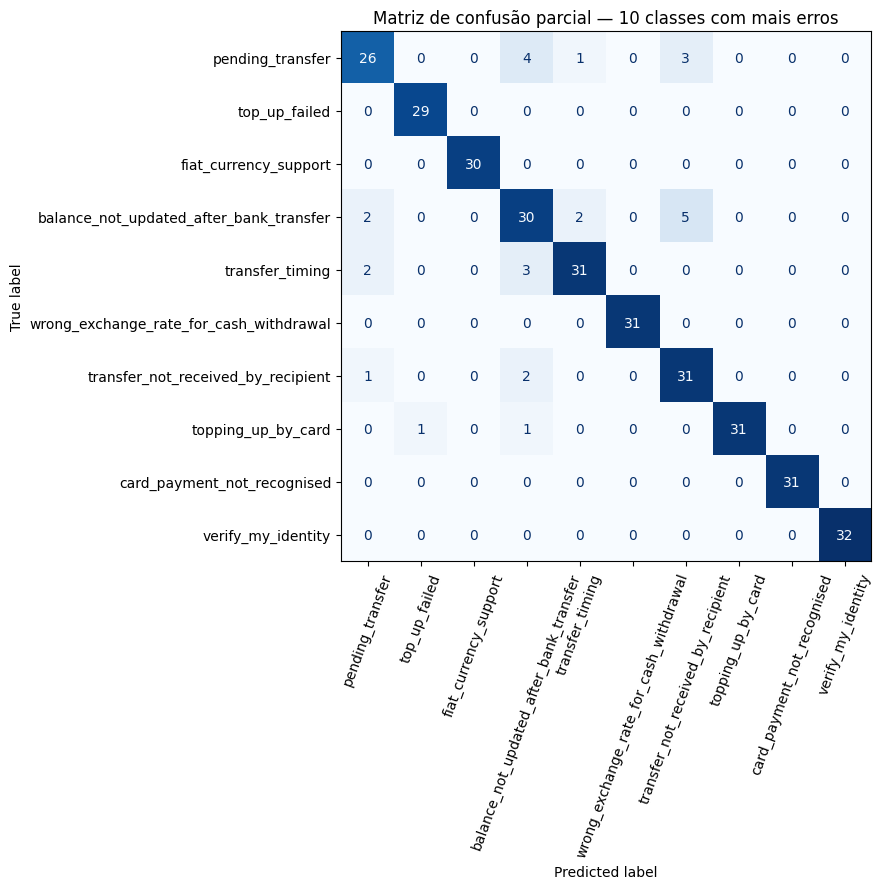

,Mensagem,Correta,Prevista
1347,Cannot access my top up.,topping_up_by_card,top_up_failed
3005,What do you need for my identity check?,verify_my_identity,why_verify_identity
2711,My transfer is pending.,balance_not_updated_after_bank_transfer,pending_transfer
2092,My card is being declined for a purchase. I bo...,reverted_card_payment?,top_up_failed
1332,how can i top up?,topping_up_by_card,top_up_limits
2503,can I have a non virtual card?,order_physical_card,getting_virtual_card
2664,can you check why I wasn't able to top up?,top_up_failed,top_up_by_cash_or_cheque
2048,how long dies it take for transfers to reflect...,transfer_timing,balance_not_updated_after_bank_transfer
2525,Why is my virtual card is being declined?,virtual_card_not_working,getting_virtual_card
1626,"I was double charged, and the second charge is...",pending_card_payment,transaction_charged_twice


Erros totais no teste: 351 de 3080.


In [ ]:
errors_df = test_df.copy()
errors_df['prediction'] = test_pred
errors_df['wrong'] = errors_df['category'] != errors_df['prediction']

worst_classes = (errors_df.loc[errors_df.wrong, 'category']
                 .value_counts().head(10).index.tolist())
mask = errors_df['category'].isin(worst_classes) & errors_df['prediction'].isin(worst_classes)
cm = confusion_matrix(errors_df.loc[mask,'category'],
                      errors_df.loc[mask,'prediction'], labels=worst_classes)
fig, ax = plt.subplots(figsize=(11,9))
ConfusionMatrixDisplay(cm, display_labels=worst_classes).plot(
    ax=ax, xticks_rotation=70, cmap='Blues', colorbar=False, values_format='d'
)
ax.set_title('Matriz de confusão parcial — 10 classes com mais erros')
plt.tight_layout()
plt.show()

examples = (errors_df.loc[errors_df.wrong, ['text','category','prediction']]
            .sample(n=min(10, int(errors_df.wrong.sum())), random_state=RANDOM_STATE)
            .rename(columns={'text':'Mensagem','category':'Correta','prediction':'Prevista'}))
display(examples)
print(f'Erros totais no teste: {errors_df.wrong.sum()} de {len(errors_df)}.')

### 5.2. Inspecionando a representação numérica

Veja quais n-gramas do texto de exemplo estão presentes no vocabulário do TF-IDF. Isso ajuda a entender que o classificador opera sobre **atributos numéricos esparsos**, não sobre uma interpretação explícita da intenção.

In [ ]:
example = 'I lost my bank card and need a replacement'
vectorizer = model.named_steps['tfidf']
vec = vectorizer.transform([example])
feature_names = vectorizer.get_feature_names_out()
active = sorted(zip(feature_names[vec.indices], vec.data), key=lambda x: -x[1])
print('Exemplo:', example)
print('Atributos não nulos:', vec.nnz)
display(pd.DataFrame(active[:15], columns=['Termo ou n-grama', 'Peso TF-IDF']))

Exemplo: I lost my bank card and need a replacement
Atributos não nulos: 12


,Termo ou n-grama,Peso TF-IDF
0,replacement,0.401792
1,bank card,0.389127
2,my bank,0.365388
3,lost my,0.327804
4,and need,0.325520
5,card and,0.309305
6,lost,0.290246
7,bank,0.265632
8,need,0.195763
9,and,0.168073


## 6. Construindo o chatbot

O SVM reconhece **intenções**, mas não escreve respostas. Adicionaremos uma pequena camada de diálogo que consulta um catálogo de respostas.

Este exemplo **não extrai entidades**, **não armazena contexto entre turnos** e **não executa transações**. Um chatbot real precisaria desses recursos, além de autenticação e integrações seguras.

**Fallback:** o `LinearSVC` fornece *margens de decisão* via `decision_function`, **não probabilidades**. Usaremos a maior margem como um sinal heurístico para rejeitar entradas pouco familiares. O limiar será calibrado **somente na validação**, com foco em detectar previsões incorretas conhecidas. Esse mecanismo **não garante** detectar mensagens fora do domínio.

In [ ]:
# Conferimos os nomes das intenções disponíveis antes de cadastrar respostas.
all_labels = set(model.classes_)
responses = {
    'lost_or_stolen_card': 'I can guide you to report a lost or stolen card. Please use the official banking app or contact your bank immediately.',
    'card_not_working': 'Please check the card status in the official app. If the issue persists, contact the bank support team.',
    "card_arrival": "You can usually check card delivery and tracking details through your bank's official app.",
    'card_linking': 'Check the card section of the banking app for instructions to link your card.',
    'cash_withdrawal_charge': 'Please review the cash withdrawal fee information in the official pricing documents.',
    'pending_cash_withdrawal': 'A pending withdrawal may take time to appear. Check the official transaction status.',
    'beneficiary_not_allowed': 'Please verify the beneficiary details and contact official support if the transfer remains blocked.',
    'cancel_transfer': 'Transfer cancellation depends on its status. Check the official app or contact support promptly.',
    'pending_transfer': 'Please check the transfer status in the official banking app.',
    'failed_transfer': 'Check the destination details and error shown in the official banking app.',
    'card_payment_wrong_exchange_rate': 'Check the exchange-rate information in your payment details and bank terms.',
    'declined_card_payment': 'Check your card settings and available balance; contact the bank if the payment is still declined.',
    "getting_virtual_card": "You can find information about virtual card availability in the bank's official app.",
    'change_pin': 'Check the official app for options to change your card PIN; do not share your PIN here.',
    'verify_my_identity': 'Identity verification should be completed only through official secure banking channels.',
    'extra_charge_on_statement': 'Review your statement and contact the bank if you do not recognize a charge.'
}
responses = {k:v for k,v in responses.items() if k in all_labels}
print(f'Respostas específicas configuradas para {len(responses)} das {len(all_labels)} intenções.')
print('Categorias com resposta:', ', '.join(sorted(responses)))

Respostas específicas configuradas para 16 das 77 intenções.
Categorias com resposta: beneficiary_not_allowed, cancel_transfer, card_arrival, card_linking, card_not_working, card_payment_wrong_exchange_rate, cash_withdrawal_charge, change_pin, declined_card_payment, extra_charge_on_statement, failed_transfer, getting_virtual_card, lost_or_stolen_card, pending_cash_withdrawal, pending_transfer, verify_my_identity


### 6.1. Selecionando um limiar de fallback (somente validação)

Para uma demonstração simples, selecionamos um limiar entre quantis das margens observadas na validação. O critério busca **reter a maior cobertura de previsões possível**, exigindo precisão de pelo menos 90% entre as previsões aceitas; se nenhum limiar satisfizer a meta, o código escolhe o que maximiza a precisão observada. Trata-se de uma heurística experimental, **não de confiança probabilística calibrada**.

A avaliação oficial de acurácia/F1 anterior continua sendo a do classificador **sem rejeição**.

In [ ]:
def max_margin(trained_model, texts):
    scores = trained_model.decision_function(texts)
    return np.max(scores, axis=1)

val_margins = max_margin(model, val_df['text'])
correct = np.asarray(val_pred) == val_df['category'].to_numpy()
quantiles = np.unique(np.quantile(val_margins, np.linspace(0, 0.95, 40)))
rows = []
for t in quantiles:
    accepted = val_margins >= t
    if accepted.any():
        rows.append({'threshold':float(t), 'coverage':float(accepted.mean()),
                     'accepted_accuracy':float(correct[accepted].mean())})
threshold_df = pd.DataFrame(rows)
feasible = threshold_df[threshold_df.accepted_accuracy >= 0.90]
if len(feasible):
    choice = feasible.sort_values(['coverage','accepted_accuracy'], ascending=False).iloc[0]
else:
    choice = threshold_df.sort_values(['accepted_accuracy','coverage'], ascending=False).iloc[0]
FALLBACK_THRESHOLD = float(choice.threshold)
print(f'Limiar escolhido: {FALLBACK_THRESHOLD:.3f}')
print(f'Cobertura estimada na validação: {choice.coverage:.1%}')
print(f'Acurácia nas previsões aceitas (validação): {choice.accepted_accuracy:.1%}')
print('ATENÇÃO: margem de decisão NÃO é probabilidade; OOD continua difícil.')

Limiar escolhido: -0.555
Cobertura estimada na validação: 97.5%
Acurácia nas previsões aceitas (validação): 90.1%
ATENÇÃO: margem de decisão NÃO é probabilidade; OOD continua difícil.


In [ ]:
class ClassicChatbot:
    def __init__(self, classifier, response_map, threshold):
        self.classifier = classifier
        self.response_map = response_map
        self.threshold = float(threshold)

    def respond(self, message: str) -> dict:
        if not isinstance(message, str) or not message.strip():
            return {'message': message, 'intent': None,
                    'response': 'Please type a banking question in English.',
                    'fallback': True, 'decision_score': None}
        intent = str(self.classifier.predict([message])[0])
        score = float(max_margin(self.classifier, [message])[0])
        low_margin = score < self.threshold
        if low_margin:
            response = ('I am not sure what you mean. Please rephrase your question '
                        'or contact the bank through an official channel.')
        elif intent in self.response_map:
            response = self.response_map[intent]
        else:
            response = (f'I understood your question as: {intent.replace("_", " ")}. '
                        'However, I do not have a specific procedure configured for it.')
        return {'message': message, 'intent': intent, 'response': response,
                'fallback': bool(low_margin or intent not in self.response_map),
                'decision_score': score}

bot = ClassicChatbot(model, responses, FALLBACK_THRESHOLD)
print(bot.respond('My card is missing. What should I do?'))

{'message': 'My card is missing. What should I do?', 'intent': 'lost_or_stolen_card', 'response': 'I can guide you to report a lost or stolen card. Please use the official banking app or contact your bank immediately.', 'fallback': False, 'decision_score': 0.19123370143077079}


## 7. Testes do chatbot

Teste mensagens mais simples, paráfrases, erros de digitação, entradas ambíguas e mensagens fora do domínio. **Se o chatbot classificar uma frase sobre culinária como um problema bancário, isso demonstra uma limitação de classificadores de conjunto fechado.**

In [ ]:
test_messages = [
    'I lost my bank card',
    'My card has not arrived yet',
    'I cannot pay with my card',
    'How can I change my PIN?',
    'My transfer is still pending',
    'Please cancel the money transfer',
    'I was charged twice for a purchase',
    'My crad is not wrking',              # erro de digitação
    'Something is wrong with my money',  # ambígua
    'What is the best pasta recipe?',    # fora do domínio
    'Tell me a joke about dinosaurs',    # fora do domínio
    'Can you explain quantum physics?'   # fora do domínio
]
results = [bot.respond(m) for m in test_messages]
display(pd.DataFrame(results)[['message','intent','fallback','decision_score','response']])

,message,intent,fallback,decision_score,response
0,I lost my bank card,lost_or_stolen_card,False,-0.003771,I can guide you to report a lost or stolen car...
1,My card has not arrived yet,card_arrival,False,-0.081261,You can usually check card delivery and tracki...
2,I cannot pay with my card,card_acceptance,True,-0.045178,I understood your question as: card acceptance...
3,How can I change my PIN?,change_pin,False,1.574437,Check the official app for options to change y...
4,My transfer is still pending,pending_transfer,False,1.275417,Please check the transfer status in the offici...
5,Please cancel the money transfer,cancel_transfer,False,0.451110,Transfer cancellation depends on its status. C...
6,I was charged twice for a purchase,transaction_charged_twice,True,1.386571,I understood your question as: transaction cha...
7,My crad is not wrking,Refund_not_showing_up,True,-0.612447,I am not sure what you mean. Please rephrase y...
8,Something is wrong with my money,declined_cash_withdrawal,True,-0.217054,I understood your question as: declined cash w...
9,What is the best pasta recipe?,exchange_rate,True,-0.469181,I understood your question as: exchange rate. ...


### 7.1. Converse com o modelo

Execute a célula abaixo e digite uma pergunta em inglês. O campo de entrada é controlado pelo Colab; a biblioteca de widgets costuma estar disponível, mas a célula também oferece uma função simples que pode ser chamada manualmente.

In [ ]:
def chat(message):
    result = bot.respond(message)
    print('Você:', result['message'])
    print('Intenção:', result['intent'])
    print('Margem de decisão (não é probabilidade):', result['decision_score'])
    print('Fallback:', result['fallback'])
    print('Chatbot:', result['response'])
    return result

# Alternativa universal: chame chat('My card is missing') em outra célula.
try:
    import ipywidgets as widgets
    from IPython.display import clear_output
    entry = widgets.Text(placeholder='Type a banking message in English...',
                         description='Mensagem:', layout=widgets.Layout(width='80%'))
    send = widgets.Button(description='Enviar', button_style='primary')
    output = widgets.Output()
    def on_send(_):
        with output:
            clear_output(wait=True)
            chat(entry.value)
    send.on_click(on_send)
    display(widgets.VBox([entry, send, output]))
except ImportError:
    print("Widgets indisponíveis. Use chat('My card is missing') em uma nova célula.")

## 8. Discussão: o que este chatbot consegue e o que não consegue?

**Pontos fortes:** treinamento rápido em CPU; resultados mensuráveis; respostas controladas; implementação clara; dispensa modelos grandes.

**Limitações:**
1. **Representação lexical:** TF-IDF não incorpora diretamente o contexto semântico profundo de uma frase.
2. **Conjunto fechado de intenções:** o classificador sempre prevê uma das 77 classes antes da regra de fallback, mesmo para mensagens que não são bancárias.
3. **Fallback heurístico:** margens de `LinearSVC` não são probabilidades e não garantem detecção de entradas fora do domínio.
4. **Sem memória de diálogo:** a implementação analisa cada mensagem de forma independente; não resolve referências como *“And what about tomorrow?”* a um turno anterior.
5. **Sem geração de texto nem ações externas:** as respostas são predefinidas; nenhuma operação real é executada.
6. **Idioma:** o conjunto de treino está em inglês; resultados em português são imprevisíveis.

**Para comparação com BERT:** utilizar os mesmos conjuntos de treino, validação e teste e as mesmas métricas. Assim, as diferenças observadas refletem principalmente o uso de representações contextuais e de pré-treinamento, além das demais diferenças entre os modelos.

## 9. Atividades -- Notebook Extra 2.1

Quem entregar essa atividade (Extra 2.1) E a atividade do Notebook Extra 2.2, e ter uma nota média (entre as duas atividades Extra 2.1 e 2.2) maior que uma nota menor de outro notebook, terá a nota menor substituida. Isso vale para demais notebooks fora o Notebook Extra e o primeiro notebook com nota substituida.

### Exercício 1 — Unigramas vs. unigramas + bigramas
Treine outro `Pipeline` usando `ngram_range=(1,1)` e compare Accuracy, F1 macro e tempo de treinamento **na validação**. Não use o teste para escolher o melhor modelo.

### Exercício 2 — Fallback fora do domínio
Compare o comportamento do chatbot para pelo menos cinco mensagens que não mencionem serviços bancários. Quantas foram rejeitadas? Explique por que uma margem alta não implica que a intenção esteja correta.

### Exercício 3 — Análise de erros
Selecione três exemplos errados, examine as duas intenções envolvidas e proponha uma mudança nos dados ou no modelo que possa reduzir a confusão.


In [ ]:
# EXERCÍCIO 1 — complete ou execute e interprete os resultados.
unigram_model = make_pipeline(ngram_range=(1,1))
t0 = time.perf_counter()
unigram_model.fit(train_df['text'], train_df['category'])
unigram_train_seconds = time.perf_counter() - t0
unigram_metrics, _ = evaluate_classifier(unigram_model, val_df, 'Unigramas (validação)')
comparison = pd.DataFrame([
    {'Modelo':'TF-IDF (1,2) + LinearSVC', 'Accuracy':val_metrics['Accuracy'],
     'F1 macro':val_metrics['F1 macro'], 'Treino (s)':training_seconds},
    {'Modelo':'TF-IDF (1,1) + LinearSVC', 'Accuracy':unigram_metrics['Accuracy'],
     'F1 macro':unigram_metrics['F1 macro'], 'Treino (s)':unigram_train_seconds}
])
display(comparison.round(3))
print('Qual representação obteve melhor resultado na validação? Por quê?')

,Modelo,Accuracy,F1 macro,Treino (s)
0,"TF-IDF (1,2) + LinearSVC",0.889,0.891,2.613
1,"TF-IDF (1,1) + LinearSVC",0.896,0.895,2.235


Qual representação obteve melhor resultado na validação? Por quê?


In [11]:
# EXERCÍCIO 1 (Complemento) — Comparação de vocabulário, métricas e número de erros na validação
vocab_12 = len(model.named_steps['tfidf'].vocabulary_)
vocab_11 = len(unigram_model.named_steps['tfidf'].vocabulary_)
_, unigram_val_pred = evaluate_classifier(unigram_model, val_df, 'Unigramas (validação)')

ex1_diag_df = pd.DataFrame([
    {
        'Modelo': 'TF-IDF (1,2) + LinearSVC',
        'Vocabulário (termos)': vocab_12,
        'Accuracy (Val)': round(val_metrics['Accuracy'], 4),
        'Precision macro (Val)': round(val_metrics['Precision macro'], 4),
        'Recall macro (Val)': round(val_metrics['Recall macro'], 4),
        'F1 macro (Val)': round(val_metrics['F1 macro'], 4),
        'Treino (s)': round(training_seconds, 3),
        'Erros na Validação (de 1501)': int((val_pred != val_df['category']).sum())
    },
    {
        'Modelo': 'TF-IDF (1,1) + LinearSVC',
        'Vocabulário (termos)': vocab_11,
        'Accuracy (Val)': round(unigram_metrics['Accuracy'], 4),
        'Precision macro (Val)': round(unigram_metrics['Precision macro'], 4),
        'Recall macro (Val)': round(unigram_metrics['Recall macro'], 4),
        'F1 macro (Val)': round(unigram_metrics['F1 macro'], 4),
        'Treino (s)': round(unigram_train_seconds, 3),
        'Erros na Validação (de 1501)': int((unigram_val_pred != val_df['category']).sum())
    }
])
display(ex1_diag_df)

,Modelo,Vocabulário (termos),Accuracy (Val),Precision macro (Val),Recall macro (Val),F1 macro (Val),Treino (s),Erros na Validação (de 1501)
0,"TF-IDF (1,2) + LinearSVC",21595,0.8894,0.898,0.891,0.891,2.613,166
1,"TF-IDF (1,1) + LinearSVC",2135,0.8961,0.9012,0.8961,0.8955,2.235,156


#### Análise e Interpretação — Exercício 1 (Unigramas vs. Unigramas + Bigramas)

**1. Qual representação obteve melhor resultado na validação?**
- A representação apenas com **unigramas (`ngram_range=(1,1)`)** obteve o melhor resultado no conjunto de validação:
  - **Accuracy (Validação):** `0,896` (`89,61%`, 156 erros em 1.501 exemplos) contra `0,889` (`88,94%`, 166 erros) do modelo com unigramas + bigramas `(1,2)` — vantagem de **+0,67 ponto percentual**.
  - **F1 macro (Validação):** `0,895` (`89,55%`) contra `0,891` (`89,10%`) do modelo `(1,2)` — vantagem de **+0,45 ponto percentual**.
  - **Tempo de treinamento:** menor na configuração `(1,1)` (`2,235 s` vs. `2,613 s`), pois o vocabulário possui apenas ~`2.135` termos, cerca de **10 vezes menor** do que os `21.595` termos de `(1,2)`.

**2. Por que os unigramas superaram os unigramas + bigramas neste cenário?**
- **Alta dimensionalidade e esparsidade (*curse of dimensionality*):** O conjunto de treino possui `8.502` mensagens curtas distribuídas em `77` intenções (~110 exemplos por classe). Ao incluir todos os bigramas sem filtro de frequência mínima (`min_df=1`), o vocabulário salta de ~`2.135` para `21.595` atributos, adicionando mais de `19.400` bigramas raros que ocorrem pouquíssimas vezes.
- **Diluição dos unigramas-chave pela normalização L2 do TF-IDF:** Como o `TfidfVectorizer` normaliza cada vetor de documento pela norma L2 ($\|v\|_2 = 1$), a presença de vários bigramas raros (que recebem alto peso IDF) reduz o peso relativo das palavras individuais (unigramas) que carregam o sinal semântico mais forte em consultas bancárias curtas (ex.: *refund*, *pin*, *beneficiary*, *atm*, *exchange*, *top*, *up*).
- **Leve sobreajuste (*overfitting*) a combinações lexicais do treino:** Com o parâmetro de regularização padrão (`C=1.0`), o `LinearSVC` atribui pesos a bigramas genéricos (como *"where is"*, *"how can"*, *"can you"*) que coocorreram por acaso com determinadas classes no treino, prejudicando a generalização na validação.
- **Importância metodológica de usar apenas a validação:** A escolha entre representações e hiperparâmetros deve ser feita exclusivamente com base na **validação**, preservando o conjunto de **teste oficial** como uma estimativa imparcial de desempenho final (evitando *data leakage*).

---
### Resolução do Exercício 2 — Fallback fora do domínio (OOD)

Abaixo testamos **8 mensagens completamente fora do domínio bancário** (culinária, humor, física, previsão do tempo, esportes, oficina mecânica, biblioteca/transporte e aviação). Para uma análise precisa, distinguimos na tabela as duas condições que compõem o fallback em `ClassicChatbot.respond()`:
1. **Rejeição pela margem de decisão (`decision_score < FALLBACK_THRESHOLD`):** quando o escore máximo do `LinearSVC` fica abaixo do limiar calibrado na validação (`-0,555`), retornando *"I am not sure what you mean..."*.
2. **Fallback por ausência de resposta no catálogo (`intent not in response_map`):** quando o classificador **aceita** a mensagem pela margem (`decision_score >= -0,555`), mas a intenção prevista está entre as 61 classes sem resposta específica configurada (retornando *"I understood your question as: ..."*).

In [12]:
# EXERCÍCIO 2 — Avaliação do chatbot para mensagens fora do domínio (OOD)
ood_messages = [
    'What is the best pasta recipe?',                     # culinária
    'Tell me a joke about dinosaurs',                     # humor
    'Can you explain quantum physics?',                   # ciência
    'What is the weather forecast for tomorrow in Tokyo?',# clima
    'Who won the football World Cup in 2022?',            # esportes
    'My car engine is not working after the oil change.', # oficina mecânica (contém 'not working' / 'change')
    'I lost my library book and my train ticket yesterday.', # cotidiano (contém 'lost my' / 'yesterday')
    'When is the arrival of the next flight to London?'   # aviação (contém 'arrival')
]

ood_rows = []
for msg in ood_messages:
    res = bot.respond(msg)
    score = res['decision_score']
    rej_margin = score < FALLBACK_THRESHOLD
    in_map = res['intent'] in responses
    ood_rows.append({
        'Mensagem fora do domínio (OOD)': res['message'],
        'Intenção Prevista': res['intent'],
        'Margem (decision_score)': round(score, 4),
        'Rejeitada pela Margem (< -0.555)': rej_margin,
        'Possui Resposta Cadastrada': in_map,
        'Fallback Final': res['fallback'],
        'Resposta do Chatbot': res['response']
    })

ood_df = pd.DataFrame(ood_rows)
display(ood_df)

n_total_ood = len(ood_df)
n_rej_margin = int(ood_df['Rejeitada pela Margem (< -0.555)'].sum())
n_acc_margin = n_total_ood - n_rej_margin
n_fallback_total = int(ood_df['Fallback Final'].sum())
n_false_active_response = int((~ood_df['Fallback Final']).sum())

print(f'Limiar de margem (FALLBACK_THRESHOLD): {FALLBACK_THRESHOLD:.3f}')
print(f'Total de mensagens fora do domínio testadas: {n_total_ood}')
print(f'  - Rejeitadas pelo limiar de margem (score < {FALLBACK_THRESHOLD:.3f}): {n_rej_margin} de {n_total_ood} ({n_rej_margin/n_total_ood:.1%})')
print(f'  - Aceitas pelo limiar de margem (score >= {FALLBACK_THRESHOLD:.3f}): {n_acc_margin} de {n_total_ood} ({n_acc_margin/n_total_ood:.1%})')
print(f'  - Acionaram fallback total (margem baixa OU intenção sem resposta cadastrada): {n_fallback_total} de {n_total_ood} ({n_fallback_total/n_total_ood:.1%})')
print(f'  - Receberam resposta bancária específica mesmo sendo fora do domínio (fallback=False): {n_false_active_response} de {n_total_ood} ({n_false_active_response/n_total_ood:.1%})')

,Mensagem fora do domínio (OOD),Intenção Prevista,Margem (decision_score),Rejeitada pela Margem (< -0.555),Possui Resposta Cadastrada,Fallback Final,Resposta do Chatbot
0,What is the best pasta recipe?,exchange_rate,-0.4692,False,False,True,"I understood your question as: exchange rate. However, I do not have a specific procedure configured for it."
1,Tell me a joke about dinosaurs,get_disposable_virtual_card,-0.6852,True,False,True,I am not sure what you mean. Please rephrase your question or contact the bank through an official channel.
2,Can you explain quantum physics?,top_up_reverted,-0.5942,True,False,True,I am not sure what you mean. Please rephrase your question or contact the bank through an official channel.
3,What is the weather forecast for tomorrow in Tokyo?,fiat_currency_support,-0.5164,False,False,True,"I understood your question as: fiat currency support. However, I do not have a specific procedure configured for it."
4,Who won the football World Cup in 2022?,receiving_money,-0.5819,True,False,True,I am not sure what you mean. Please rephrase your question or contact the bank through an official channel.
5,My car engine is not working after the oil change.,card_not_working,0.0487,False,True,False,"Please check the card status in the official app. If the issue persists, contact the bank support team."
6,I lost my library book and my train ticket yesterday.,lost_or_stolen_card,0.0768,False,True,False,I can guide you to report a lost or stolen card. Please use the official banking app or contact your bank immediately.
7,When is the arrival of the next flight to London?,card_arrival,-0.4731,False,True,False,You can usually check card delivery and tracking details through your bank's official app.


Limiar de margem (FALLBACK_THRESHOLD): -0.555
Total de mensagens fora do domínio testadas: 8
  - Rejeitadas pelo limiar de margem (score < -0.555): 3 de 8 (37.5%)
  - Aceitas pelo limiar de margem (score >= -0.555): 5 de 8 (62.5%)
  - Acionaram fallback total (margem baixa OU intenção sem resposta cadastrada): 5 de 8 (62.5%)
  - Receberam resposta bancária específica mesmo sendo fora do domínio (fallback=False): 3 de 8 (37.5%)


#### Análise e Interpretação — Exercício 2 (Fallback fora do domínio)

**1. Quantas mensagens foram rejeitadas?**
- Das **8 mensagens fora do domínio (OOD)** avaliadas:
  - Apenas **3 mensagens (`37,5%`) foram rejeitadas pelo limiar de margem de decisão** (`decision_score < -0,555`): as perguntas sobre *dinossauros* (`-0,6852`), *física quântica* (`-0,5942`) e *Copa do Mundo* (`-0,5819`), que praticamente não possuem termos relevantes no vocabulário bancário.
  - **5 mensagens (`62,5%`) não foram rejeitadas pela margem** (`decision_score >= -0,555`). Duas delas (*receita de massa* → `exchange_rate` com `-0,4692` e *previsão do tempo em Tóquio* → `fiat_currency_support` com `-0,5164`) só caíram no fallback secundário porque essas intenções não tinham resposta cadastrada no dicionário `responses`.
  - **3 mensagens (`37,5%`) tiveram `fallback = False`** e receberam instruções bancárias específicas como se fossem clientes reais relatando problemas com cartões:
    - *"My car engine is not working after the oil change."* → prevista como `card_not_working` (margem **`+0,0487`**);
    - *"I lost my library book and my train ticket yesterday."* → prevista como `lost_or_stolen_card` (margem **`+0,0768`**);
    - *"When is the arrival of the next flight to London?"* → prevista como `card_arrival` (margem **`-0,4731`**, acima do limiar `-0,555`).

**2. Por que uma margem alta NÃO implica que a intenção esteja correta?**
- **Suposição de Mundo Fechado (*Closed-World Assumption*):** O `LinearSVC` é um classificador discriminativo treinado apenas com exemplos das 77 intenções bancárias. Ele divide todo o espaço vetorial em 77 regiões sem estimar a densidade de probabilidade $P(x \in \text{domínio bancário})$ e sem uma classe de rejeição explícita.
- **Distância geométrica ao hiperplano $\neq$ Probabilidade calibrada:** O valor retornado por `decision_function(x)` é o produto escalar $s_c(x) = w_c^\top x + b_c$ (distância algébrica ao hiperplano separador *One-vs-Rest* da classe $c$). Uma margem alta indica apenas que os termos presentes na frase puxam o vetor na direção positiva daquela classe em comparação às *outras 76 classes bancárias*, e não que o tema da frase seja financeiro.
- **Descarte de palavras fora do vocabulário (OOV) + Normalização L2 do TF-IDF:** Quando o usuário digita *"I lost my library book and my train ticket yesterday"*, os substantivos que revelam o domínio real (*library*, *train*, *ticket*) são ignorados por serem OOV (ou irrelevantes no corpus bancário). Em seguida, o `TfidfVectorizer` **normaliza o vetor restante para norma unitária ($\|x\|_2 = 1$)**, fazendo com que n-gramas cotidianos compartilhados — como `'lost'`, `'lost my'`, `'not working'`, `'change'` ou `'arrival'` — recebam pesos TF-IDF altíssimos e ativem fortemente os coeficientes das classes `lost_or_stolen_card`, `card_not_working` e `card_arrival`.

---
### Resolução do Exercício 3 — Análise de erros

Abaixo selecionamos **três exemplos classificados incorretamente** no conjunto de teste oficial (índices `2503`, `3005` e `2048` exibidos na Seção 8), inspecionamos o par de intenções envolvido (`Correta` vs. `Prevista`) e os termos que levaram o modelo ao erro.

In [13]:
# EXERCÍCIO 3 — Seleção e inspeção de 3 exemplos classificados incorretamente no conjunto de teste
selected_cases = [
    (2503, "Negação composicional ('non virtual card' -> cartão físico)"),
    (3005, "Sobreposição lexical ('identity check') e granularidade fina ('What' vs 'Why')"),
    (2048, "Erro de digitação ('dies' por 'does') + ambiguidade entre prazo e saldo não atualizado")
]

ex3_rows = []
for idx, reason in selected_cases:
    row = errors_df.loc[idx]
    ex3_rows.append({
        'ID Teste': idx,
        'Mensagem': row['text'],
        'Intenção Correta': row['category'],
        'Intenção Prevista': row['prediction'],
        'Fenômeno Linguístico / Causa Principal': reason
    })

ex3_df = pd.DataFrame(ex3_rows)
display(ex3_df)

for rank, (idx, _) in enumerate(selected_cases, start=1):
    row = errors_df.loc[idx]
    print(f'=== Caso {rank} (Índice {idx}) ===')
    print(f'Mensagem: "{row["text"]}"')
    print(f'Intenção Correta : {row["category"]}')
    print(f'Intenção Prevista: {row["prediction"]}\n')

,ID Teste,Mensagem,Intenção Correta,Intenção Prevista,Fenômeno Linguístico / Causa Principal
0,2503,can I have a non virtual card?,order_physical_card,getting_virtual_card,Negação composicional ('non virtual card' -> cartão físico)
1,3005,What do you need for my identity check?,verify_my_identity,why_verify_identity,Sobreposição lexical ('identity check') e granularidade fina ('What' vs 'Why')
2,2048,how long dies it take for transfers to reflect...,transfer_timing,balance_not_updated_after_bank_transfer,Erro de digitação ('dies' por 'does') + ambiguidade entre prazo e saldo não atualizado


=== Caso 1 (Índice 2503) ===
Mensagem: "can I have a non virtual card?"
Intenção Correta : order_physical_card
Intenção Prevista: getting_virtual_card
Termos ativos dominantes: 'virtual', 'virtual card', 'have virtual', 'card'

=== Caso 2 (Índice 3005) ===
Mensagem: "What do you need for my identity check?"
Intenção Correta : verify_my_identity
Intenção Prevista: why_verify_identity
Termos ativos dominantes: 'identity', 'identity check', 'my identity', 'what do'

=== Caso 3 (Índice 2048) ===
Mensagem: "how long dies it take for transfers to reflect..."
Intenção Correta : transfer_timing
Intenção Prevista: balance_not_updated_after_bank_transfer
Termos ativos dominantes: 'transfers', 'reflect', 'how long', 'take for'


#### Análise Detalhada dos 3 Casos e Propostas de Melhoria — Exercício 3

1. **Caso 1 — Negação e composição semântica (`ID 2503`: *"can I have a non virtual card?"*)**
   - **Intenções envolvidas:** `order_physical_card` (*Correta*) vs. `getting_virtual_card` (*Prevista*).
   - **Diagnóstico da confusão:** O usuário deseja solicitar um **cartão físico**, mas expressa isso pela construção negativa *"non virtual card"*. Como a representação TF-IDF de unigramas e bigramas soma pesos de termos quase independentemente, os atributos `'virtual'` e `'virtual card'` possuem pesos fortemente positivos para `getting_virtual_card` e negativos para `order_physical_card`, fazendo o classificador linear prever exatamente o oposto do que o cliente pediu.
   - **Proposta de mudança nos dados ou no modelo:**
     - *Nos dados:* Realizar *data augmentation* na classe `order_physical_card` incluindo paráfrases negativas e contrastivas (*"non-virtual card"*, *"a real card, not virtual"*).
     - *No modelo:* Incluir trigramas (`ngram_range=(1,3)`) para registrar `'non virtual card'` como unidade léxica ou migrar para arquiteturas baseadas em **Transformers / embeddings contextuais (ex.: BERT)**, cujo mecanismo de autoatenção modela o escopo da negação sobre o adjetivo.

2. **Caso 2 — Sobreposição lexical e alta granularidade entre classes (`ID 3005`: *"What do you need for my identity check?"*)**
   - **Intenções envolvidas:** `verify_my_identity` (*Correta*) vs. `why_verify_identity` (*Prevista*).
   - **Diagnóstico da confusão:** Ambas as classes pertencem ao mesmo subdomínio (verificação de identidade) e compartilham os termos de maior peso IDF (`'identity'`, `'identity check'`, `'my identity'`). A distinção está apenas no tipo de pergunta: `verify_my_identity` foca no **procedimento/documentos necessários** (*"What do you need..."*), enquanto `why_verify_identity` questiona a **razão/obrigatoriedade** da verificação. Como o bigrama `'identity check'` é muito frequente em `why_verify_identity`, o classificador confunde as duas intenções.
   - **Proposta de mudança nos dados ou no modelo:**
     - *Nos dados / taxonomia do produto:* **Unificar ou agrupar intenções irmãs excessivamente granulares** em uma única intenção de atendimento (já que uma boa resposta sobre verificação de identidade pode informar tanto *por que* ela é exigida quanto *quais documentos* são aceitos).
     - *No modelo:* Se a separação for obrigatória, destacar marcadores interrogativos de início de frase (como *features* posicionais `<START>_what` vs. `<START>_why`) ou utilizar um modelo pré-treinado sensível à semântica da pergunta.

3. **Caso 3 — Erro de digitação (*typo*) + ambiguidade pragmática (`ID 2048`: *"how long dies it take for transfers to reflect..."*)**
   - **Intenções envolvidas:** `transfer_timing` (*Correta*) vs. `balance_not_updated_after_bank_transfer` (*Prevista*).
   - **Diagnóstico da confusão:** O usuário cometeu um erro de digitação em **`'dies'`** (em vez de **`'does'`**). Em um vetorizador puramente baseado em palavras, esse *typo* destrói os bigramas característicos de `transfer_timing` (`'long does'`, `'does it'`, `'it take'`). Sem esses bigramas, os termos restantes (`'transfers'`, `'reflect'`) puxam a decisão para `balance_not_updated_after_bank_transfer`.
   - **Proposta de mudança nos dados ou no modelo:**
     - *No modelo:* Combinar o TF-IDF de palavras com **n-gramas de caracteres** via `FeatureUnion` (`TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5))`), tornando o classificador robusto a variações ortográficas e *typos* (*"dies"* $\approx$ *"does"*, *"crad"* $\approx$ *"card"*).
     - *No fluxo de diálogo:* Quando a diferença de margem entre as duas intenções mais prováveis (`transfer_timing` e `balance_not_updated_after_bank_transfer`) for pequena, acionar uma **pergunta de desambiguação** ao usuário.

---
## 10. Referências, Pergunta de Fechamento e Conclusão

- **BANKING77:** [PolyAI — Task-specific datasets](https://github.com/PolyAI-LDN/task-specific-datasets); Casanueva et al., *Efficient Intent Detection with Dual Sentence Encoders* (2020).
- **Scikit-learn:** [TfidfVectorizer](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html), [LinearSVC](https://scikit-learn.org/stable/modules/generated/sklearn.svm.LinearSVC.html), [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html).

### Resposta à Pergunta de Fechamento
> **Pergunta:** *Um resultado alto na classificação das 77 intenções significa, necessariamente, que construímos um bom chatbot? Explique a diferença entre desempenho do classificador e sucesso de uma conversa.*

**Não.** Alcançar cerca de **88,6% a 89,6% de Accuracy e F1 macro** nas 77 intenções mostra que o classificador `TF-IDF + LinearSVC` é um excelente *baseline* de Compreensão de Linguagem Natural (NLU) para frases isoladas dentro do domínio, mas **desempenho do classificador** e **sucesso de uma conversa** são conceitos diferentes:

1. **Classificação de Turno Único vs. Resolução de Ponta a Ponta:**
   - O classificador avalia apenas se um rótulo correto foi atribuído a uma mensagem estática. Já uma conversa bem-sucedida exige que o usuário **resolva seu problema real** de forma clara, segura e eficiente.
2. **Extração de Entidades (*Slot Filling*) e Integração com Sistemas (*Backend*):**
   - Identificar a intenção `cancel_transfer` ou `declined_card_payment` é apenas o primeiro passo. Um bom chatbot bancário precisa extrair entidades (valor, data, destinatário, final do cartão), autenticar o cliente e consultar APIs transacionais para dar uma resposta personalizada ou executar a ação — enquanto nosso protótipo possui respostas estáticas para apenas 16 das 77 intenções.
3. **Gerenciamento de Estado e Contexto Multi-turno (*Dialogue Management*):**
   - Conversas reais envolvem múltiplos turnos, pronomes e referências anafóricas (ex.: Turno 1: *"How long does a transfer take?"* → Turno 2: *"Mine is still pending since yesterday"*). Um classificador sem memória processa cada mensagem isoladamente e perde o contexto acumulado.
4. **Tratamento de Incerteza, Desambiguação e Fora do Domínio (OOD):**
   - Como vimos no Exercício 2, a margem do `LinearSVC` não é uma probabilidade calibrada e falha em rejeitar frases fora do domínio que compartilham palavras comuns (*"lost"*, *"not working"*, *"arrival"*). Além disso, erros em intenções críticas de segurança (como bloqueio de cartão ou fraude) têm custo muito maior para o usuário do que erros em dúvidas informativas, embora tenham o mesmo peso na acurácia.
5. **Métricas Offline de ML vs. Métricas de Produto Conversacional:**
   - Enquanto o classificador é avaliado por *Accuracy* e *F1 macro* em um conjunto de teste fixo, o sucesso do chatbot é medido por **Taxa de Resolução no Primeiro Contato (FCR)**, **Taxa de Contenção com Transbordo Humano Adequado**, **Número de Turnos até a Resolução** e **Satisfação do Usuário (CSAT / NPS)**.

### Síntese Final do Notebook
- **Eficiência do Modelo Clássico:** O pipeline `TF-IDF + LinearSVC` entrega alta competitividade (**88,6% no teste oficial** com `(1,2)` e **89,6% na validação** com `(1,1)`), treinando em **~2,2 a 2,6 segundos em CPU** e inferindo em menos de **0,08 ms por mensagem**.
- **Principais Limitações Diagnosticadas:** Sensibilidade a negações e composicionalidade (*"non virtual card"*), vulnerabilidade a erros de digitação (*"dies"*), confusão entre intenções com alta sobreposição lexical (`verify_my_identity` vs. `why_verify_identity`) e ausência de rejeição probabilística calibrada para entradas fora do domínio — fatores que motivam o uso de modelos baseados em **Transformers (BERT)** no Notebook Extra 2.2.

---
Comentários:
Ferramenta: ChatGPT
Utilização: Utilizado para melhorar escrita e fluídez do texto

Ferramenta: Gemini
Utilização: Utilizado para desenvolvimento de código e estruturação da análise dos exercícios